# RQ2: 72 h forecast error across ocean regimes — eight models

This notebook compares two baselines (Persistence and Mean Flow), VAR(1), Ridge, FNN, KNN, Random Forest, and Extra Tree across Shelf, Kuroshio Core, Transition, and Other Offshore.

**Displayed names:** FNN and KNN use the *Optimised FNN* and *Optimised KNN* test predictions; Random Forest uses the *original Random Forest* test predictions; Extra Tree uses the original Extra Trees model. The short chart labels do not change which trained models produced the errors.

The embedded data contain actual per-case endpoint errors for the same 757 test cases per model. No predictions are estimated or filled in.

## Where was the original Kuroshio Core?

The map below uses the project's **GLORYS 1994–2022 mean surface-current figure** as the background. **The large white land area labelled **Japan** is Kyushu. Other white areas can be land, islands, or cells with no GLORYS ocean value; coloured areas are ocean current speed.** Arrows show current direction. The two highlighted regions are the original Kuroshio Core components.

The project selected cells where the magnitude of the **mean velocity vector** was at least **0.5 m/s**, grouped adjacent cells using **8-neighbour connected-component analysis**, and chose the two largest components. The southwest component is **Core 1** (806 grid cells); the northeast is **Core 2** (901 grid cells).

| Component | Longitude range | Latitude range |
|:--|:--|:--|
| Core 1 | 124.125–130.458°E | 25.542–30.542°N |
| Core 2 | 131.208–135.958°E | 29.625–33.458°N |

**Source and precision:** The ZIP includes the two original PNG figures and `RQ2/data/current_components_0p5.csv`, but not the GLORYS climatology or component-label NetCDF grids. The highlighted shapes were traced from the project's saved component figure and overlaid on its saved current figure. They show the selected location faithfully but have image-derived edges; they are not a fresh numerical segmentation.


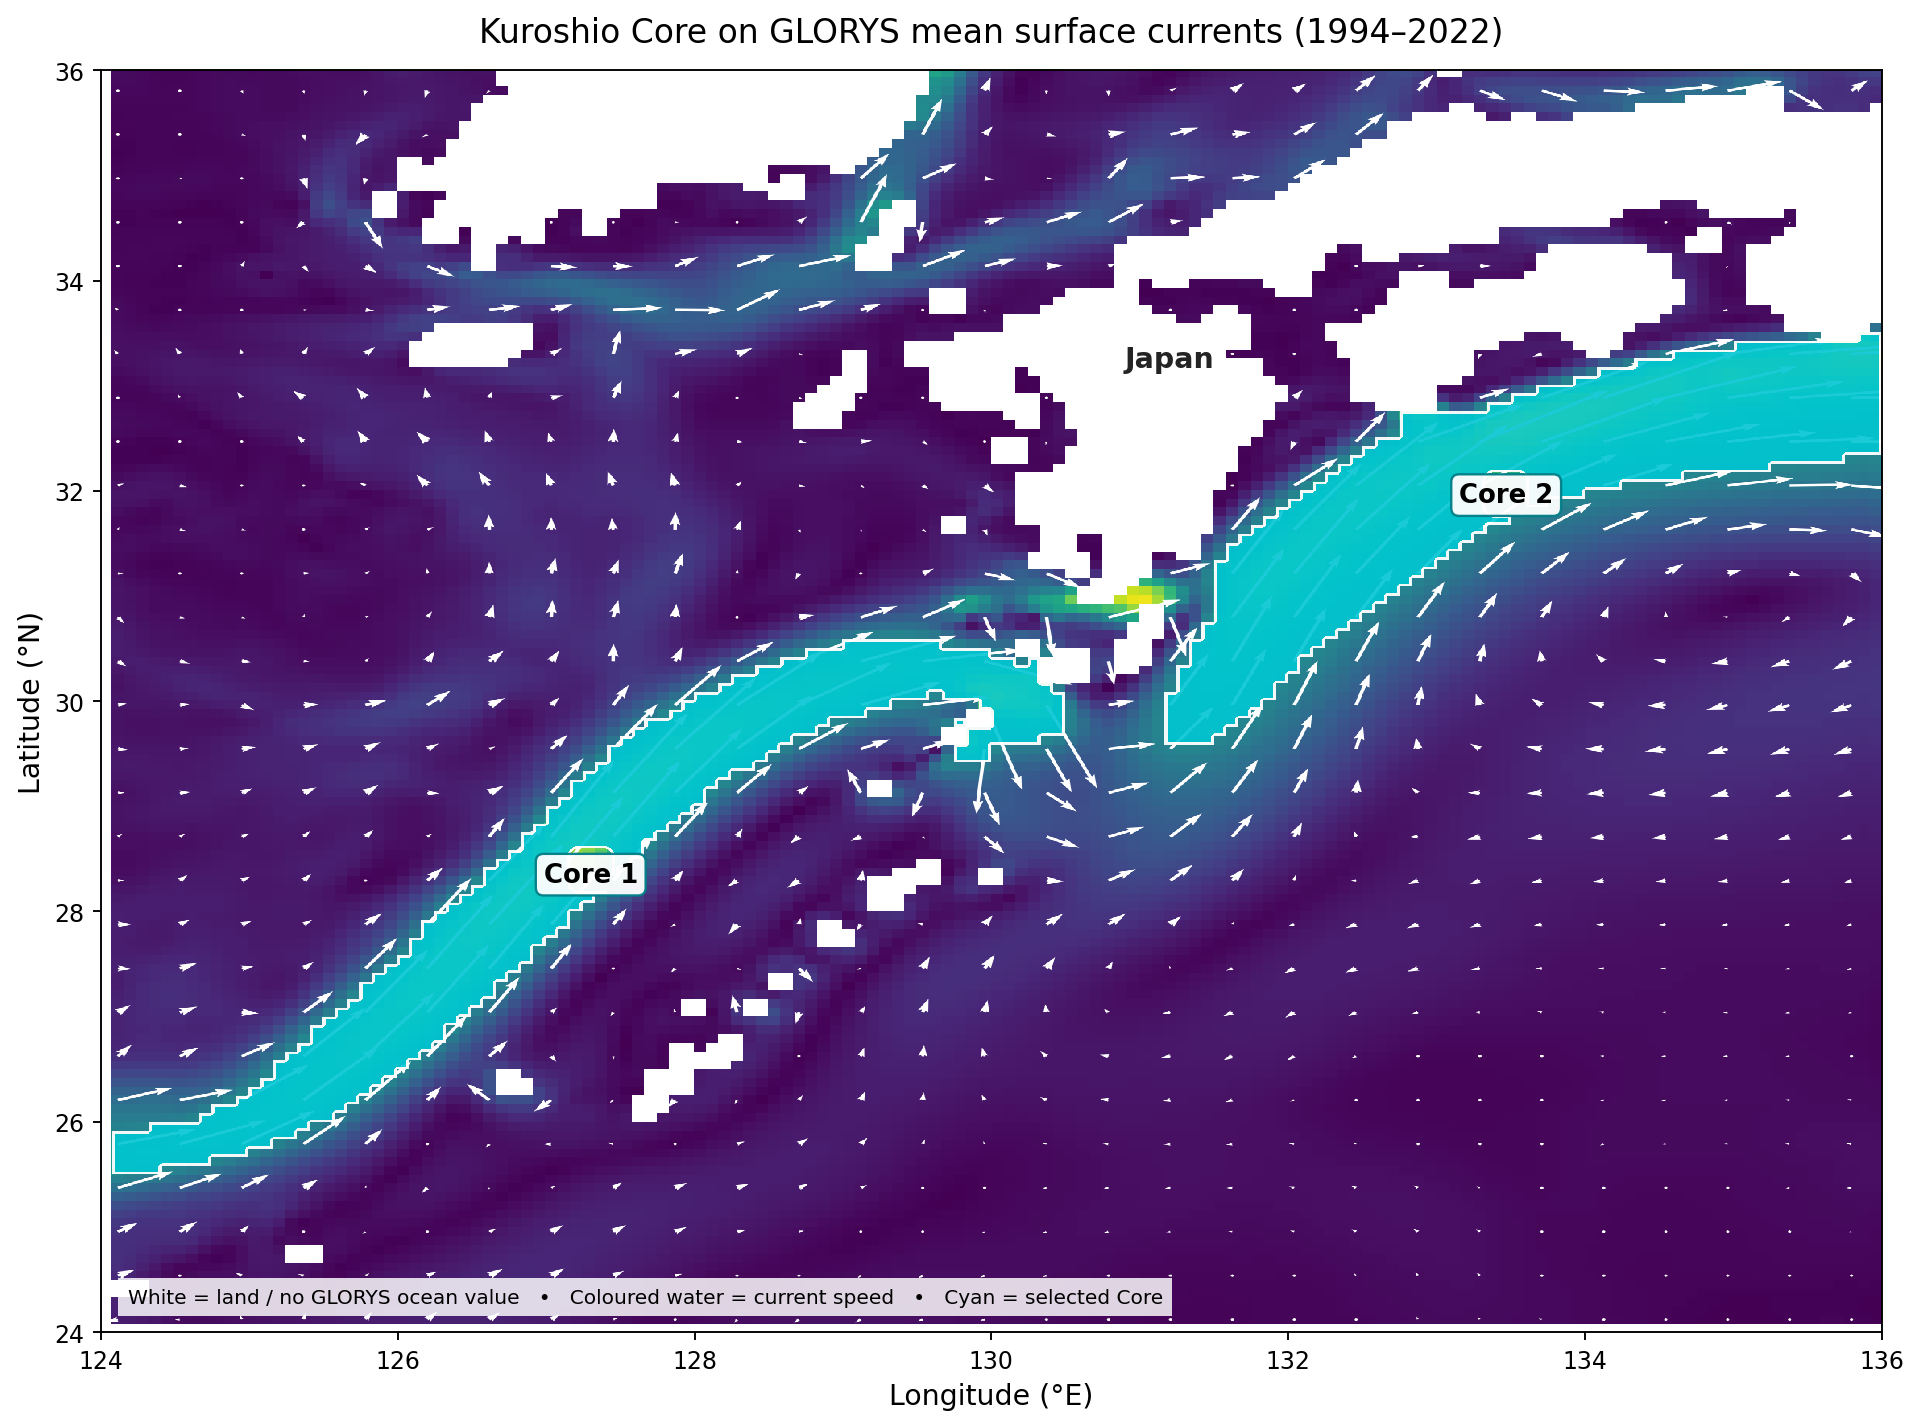

*White = land / no GLORYS ocean value; coloured water = mean current; cyan bands = the two selected Kuroshio Core components.*

## Data provenance and checks

- Regime labels and the first four model errors come from `RQ2/data/rq2_test_model_errors_long.csv` (test partition).
- Chart label **FNN** comes from `output/rq1/zh/optimised_fnn_test_case_metrics.csv`.
- Chart label **KNN** comes from `output/rq1/zh/optimised_knn_test_case_metrics.csv`.
- Chart label **Random Forest** comes from `output/rq1/zh/random_forest_test_case_metrics.csv` in the full project copy.
- Chart label **Extra Tree** comes from `output/rq1/zh/extra_trees_test_case_metrics.csv` in the full project copy.

All four added models were matched to the RQ2 test cases by `forecast_case_id`, with 757 matching drifter IDs each. The two statistics are `median(error_72h_km)` and `sqrt(mean(error_72h_km**2))`. Checksums below identify the source files used for the embedded data.

In [5]:
import base64, gzip, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

# Actual per-case test errors from the source files listed below.
EMBEDDED_CSV_GZIP_BASE64 = """..."""
errors = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(EMBEDDED_CSV_GZIP_BASE64))))
errors.head()

,forecast_case_id,ID,regime,model,error_72h_km
0,80,39616,Shelf,Extra Tree,28.666257
1,80,39616,Shelf,FNN,13.024843
2,80,39616,Shelf,KNN,3.189380
3,80,39616,Shelf,Mean Flow,16.879818
4,80,39616,Shelf,Persistence,20.677322


In [6]:
REGIMES = ["Shelf", "Kuroshio Core", "Transition", "Other Offshore"]
MODELS = ["Persistence", "Mean Flow", "VAR(1)", "Ridge", "FNN", "KNN", "Random Forest", "Extra Tree"]
required = {"forecast_case_id", "ID", "regime", "model", "error_72h_km"}
assert required.issubset(errors.columns)
assert len(errors) == 757 * 8, "Expected 757 actual test predictions for each of 8 models"
assert not errors[["forecast_case_id", "model"]].duplicated().any()
assert set(errors.regime) == set(REGIMES) and set(errors.model) == set(MODELS)
assert np.isfinite(errors.error_72h_km).all() and errors.error_72h_km.ge(0).all()
case_sets = errors.groupby("model").forecast_case_id.apply(set)
assert all(ids == case_sets.iloc[0] for ids in case_sets), "Model test cases do not match"
assert errors.groupby("model").forecast_case_id.nunique().eq(757).all()
print("Verified: 8 models × 757 matching test cases; no missing or invalid errors.")
print("Regime test-case counts:")
display(errors.loc[errors.model.eq("Persistence"), "regime"].value_counts().reindex(REGIMES).rename("n_cases"))

Verified: 8 models × 757 matching test cases; no missing or invalid errors.
Regime test-case counts:


regime
Shelf             112
Kuroshio Core     139
Transition        165
Other Offshore    341
Name: n_cases, dtype: int64

In [7]:
summary = (errors.groupby(["regime", "model"], observed=True)
           .agg(n_cases=("forecast_case_id", "nunique"),
                median_72h_km=("error_72h_km", "median"),
                rmse_72h_km=("error_72h_km", lambda x: np.sqrt(np.mean(np.square(x)))))
           .reset_index())
summary["regime"] = pd.Categorical(summary.regime, categories=REGIMES, ordered=True)
summary["model"] = pd.Categorical(summary.model, categories=MODELS, ordered=True)
summary = summary.sort_values(["regime", "model"]).reset_index(drop=True)
display(summary.round(2))

,regime,model,n_cases,median_72h_km,rmse_72h_km
0,Shelf,Persistence,112,46.30,75.54
1,Shelf,Mean Flow,112,30.89,46.07
2,Shelf,VAR(1),112,33.79,46.34
3,Shelf,Ridge,112,32.66,46.35
4,Shelf,FNN,112,24.66,40.83
5,Shelf,KNN,112,24.08,40.11
6,Shelf,Random Forest,112,25.07,40.98
7,Shelf,Extra Tree,112,24.62,41.05
8,Kuroshio Core,Persistence,139,83.32,120.36
9,Kuroshio Core,Mean Flow,139,77.10,105.33


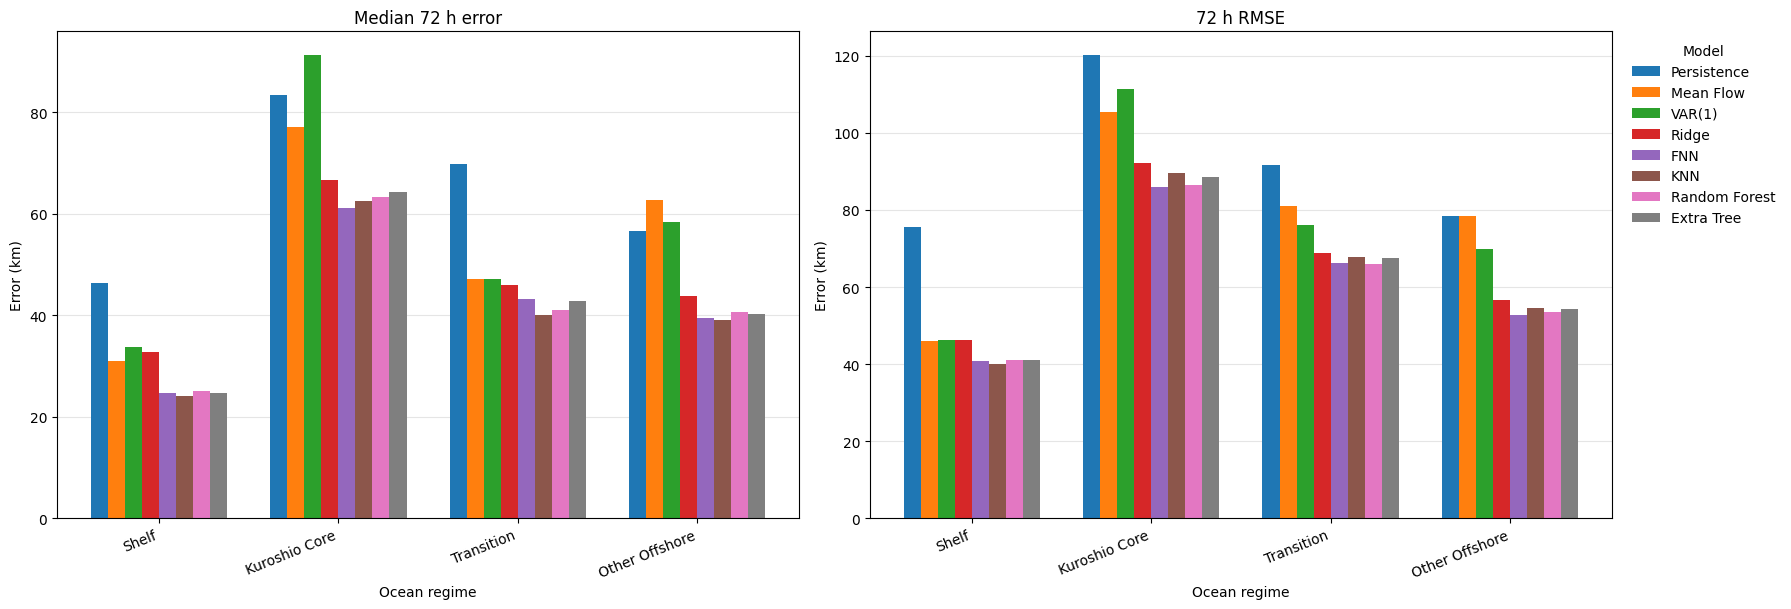

Saved: /Users/zudemac/Desktop/figure/rq2_eight_models_by_regime.png


In [10]:
# Grouped bar chart for the eight selected models.
colors = dict(zip(MODELS, plt.get_cmap("tab10").colors[:len(MODELS)]))
fig, axes = plt.subplots(1, 2, figsize=(18, 6.2), sharex=True)
x = np.arange(len(REGIMES))
width = 0.095
for ax, metric, title in zip(axes,
                             ["median_72h_km", "rmse_72h_km"],
                             ["Median 72 h error", "72 h RMSE"]):
    pivot = summary.pivot(index="regime", columns="model", values=metric).reindex(index=REGIMES, columns=MODELS)
    assert pivot.notna().all().all(), "Missing model/regime value; chart cannot be completed"
    for j, model in enumerate(MODELS):
        ax.bar(x + (j - (len(MODELS)-1)/2)*width, pivot[model].to_numpy(),
               width=width, color=colors[model], label=model)
    ax.set_title(title)
    ax.set_ylabel("Error (km)")
    ax.set_xlabel("Ocean regime")
    ax.set_xticks(x, REGIMES, rotation=22, ha="right")
    ax.grid(axis="y", alpha=.32)
    ax.set_axisbelow(True)
axes[1].legend(handles=[Patch(facecolor=colors[m], label=m) for m in MODELS],
               title="Model", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)

from pathlib import Path


FIG = Path.home() / "Desktop" / "figure"


FIG.mkdir(parents=True, exist_ok=True)


fig.tight_layout()

save_path = FIG / "rq2_eight_models_by_regime.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", save_path)



## Source file SHA-256 checksums

These hashes identify the precise source files used to build the embedded case-level data.

In [9]:
SOURCE_SHA256 = {'RQ2/data/rq2_test_model_errors_long.csv': 'fedf41c554b538d6ed7bca403c615964898279fa74216d329ae9b26c6fc22e4f', 'output/rq1/zh/optimised_fnn_test_case_metrics.csv': '18e1c12aa1eab802a395c8a65b2a3fd7d7b7d5c661dee3cd632a9ec0c1db4a50', 'output/rq1/zh/optimised_knn_test_case_metrics.csv': '700b245a6cc45830e64aacb82b5264d9f481c4155875ea104e907a9455b46c9c', 'output/rq1/zh/random_forest_test_case_metrics.csv': '028d3ba53ea398dd526fd4366698523d0076132e3b4a216e16eb393062d15e80', 'output/rq1/zh/extra_trees_test_case_metrics.csv': 'c80a083248e13f085384ad8f53f75219da15d308b73a4e99c5fbb165d847a69c'}
for path, digest in SOURCE_SHA256.items():
    print(f"{digest}  {path}")

fedf41c554b538d6ed7bca403c615964898279fa74216d329ae9b26c6fc22e4f  RQ2/data/rq2_test_model_errors_long.csv
18e1c12aa1eab802a395c8a65b2a3fd7d7b7d5c661dee3cd632a9ec0c1db4a50  output/rq1/zh/optimised_fnn_test_case_metrics.csv
700b245a6cc45830e64aacb82b5264d9f481c4155875ea104e907a9455b46c9c  output/rq1/zh/optimised_knn_test_case_metrics.csv
028d3ba53ea398dd526fd4366698523d0076132e3b4a216e16eb393062d15e80  output/rq1/zh/random_forest_test_case_metrics.csv
c80a083248e13f085384ad8f53f75219da15d308b73a4e99c5fbb165d847a69c  output/rq1/zh/extra_trees_test_case_metrics.csv


### Chart export

The chart cell saves the PNG under `RQ2/figures/eight_models_by_regime` in the project. It does not write to the Desktop.